# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to six slides (one for each of the topics/questions in the 'Get to work!' section); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

# Load dataset 

In [ ]:
import pandas as pd


splits = {'train': 'data/train-00000-of-00001.parquet', 'test': 'data/test-00000-of-00001.parquet'}
df = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["train"])

In [3]:
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
}))

print(f"Reviews: {len(df):,}")
print(f"Duplicate review texts: {df['text'].duplicated().sum():,}")
print(f"Empty reviews: {df['text'].fillna('').str.strip().eq('').sum():,}")

class_balance = (
    df.groupby(["label", "label_text"])
    .size()
    .rename("count")
    .to_frame()
)
class_balance["percent"] = (100 * class_balance["count"] / len(df)).round(2)
display(class_balance)

,dtype,missing
text,str,0
label,int64,0
label_text,str,0


Reviews: 24,904
Duplicate review texts: 0
Empty reviews: 0


,,count,percent
label,label_text,,
0,negative,12432,49.92
1,positive,12472,50.08


characters                    words                 
                mean median min    max   mean median min   max
sentiment                                                     
negative      1304.2  977.0  52   8969  231.1  175.0  10  1522
positive      1348.5  982.0  70  13704  236.9  174.0  12  2470

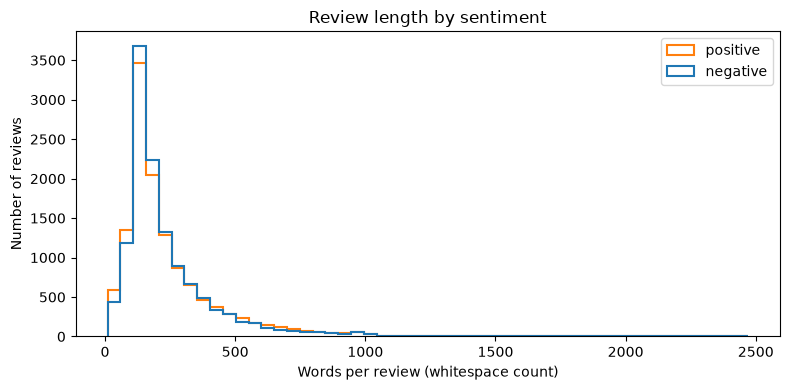

In [4]:
import matplotlib.pyplot as plt

review_lengths = pd.DataFrame({
    "sentiment": df["label_text"],
    "characters": df["text"].fillna("").str.len(),
    "words": df["text"].fillna("").str.split().str.len(),
})

display(
    review_lengths.groupby("sentiment")[["characters", "words"]]
    .agg(["mean", "median", "min", "max"])
    .round(1)
)

groups = list(review_lengths.groupby("sentiment"))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(
    [group["words"] for _, group in groups],
    bins=50,
    histtype="step",
    linewidth=1.5,
    label=[sentiment for sentiment, _ in groups],
)
ax.set(
    title="Review length by sentiment",
    xlabel="Words per review (whitespace count)",
    ylabel="Number of reviews",
)
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
# Inspect the shortest and longest cleaned reviews by whitespace word count.
review_sizes = df[["text", "label_text"]].assign(
    word_count=df["text"].fillna("").str.split().str.len()
)

for title, reviews in [
    ("5 shortest reviews", review_sizes.nsmallest(5, "word_count")),
    ("5 longest reviews", review_sizes.nlargest(5, "word_count")),
]:
    print(f"\n{title}\n" + "=" * len(title))
    for index, row in reviews.iterrows():
        print(f"\nRow {index} | {row['label_text']} | {row['word_count']} words")
        print(row["text"])


5 shortest reviews

Row 2401 | negative | 10 words
I wouldn't rent this one even on dollar rental night.

Row 10872 | negative | 10 words
this movie is terrible but it has some good effects.

Row 372 | negative | 11 words
you'd better choose paul verhoeven's even if you have watched it.

Row 12053 | negative | 12 words
ming the merciless does a little bardwork and a movie most foul!

Row 16993 | positive | 12 words
adrian pasdar is excellent is this film. he makes a fascinating woman.

5 longest reviews

Row 13685 | positive | 2459 words
match 1: tag team table match bubba ray and spike dudley vs eddie guerrero and chris benoit bubba ray and spike dudley started things off with a tag team table match against eddie guerrero and chris benoit. according to the rules of the match, both opponents have to go through tables in order to get the win. benoit and guerrero heated up early on by taking turns hammering first spike and then bubba ray. A german suplex by benoit to bubba took the wind

We replace HTML tags with spaces, decode HTML entities, and collapse repeated whitespace. Words are lowercased (e.g., `Read` → `read`), except all-caps words such as `AWFUL`, which retain their emphasis. The original reviews are preserved in `text_original`, while `text` contains the normalized reviews.

In [6]:
import re
from html.parser import HTMLParser


class ReviewHTMLParser(HTMLParser):
    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []

    def handle_starttag(self, tag, attrs):
        self.parts.append(" ")

    def handle_endtag(self, tag):
        self.parts.append(" ")

    def handle_data(self, data):
        self.parts.append(data)


def normalize_review(text):
    parser = ReviewHTMLParser()
    parser.feed(text)
    parser.close()
    text = "".join(parser.parts)
    text = re.sub(
        r"[^\W\d_]+(?:['’][^\W\d_]+)*",
        lambda match: match[0] if match[0].isupper() else match[0].lower(),
        text,
    )
    return " ".join(text.split())


if "text_original" not in df.columns:
    df["text_original"] = df["text"].copy()
df["text"] = df["text_original"].map(normalize_review, na_action="ignore")
display(df[["text_original", "text"]].head(3))


,text_original,text
0,I rented I AM CURIOUS-YELLOW from my video sto...,I rented I AM CURIOUS-YELLOW from my video sto...
1,"""I Am Curious: Yellow"" is a risible and preten...","""I am curious: yellow"" is a risible and preten..."
2,If only to avoid making this type of film in t...,if only to avoid making this type of film in t...


## Tf-idf embedding

## Qwen embedding model

Use a frozen pretrained Qwen model as the third document representation. The
configurable default is `Qwen/Qwen3-Embedding-0.6B`; change `QWEN_MODEL_ID` for
another Qwen3 embedding size if you have sufficient memory.

Additional dependencies (install manually when ready; this notebook does not
install packages automatically):

```bash
python -m pip install 'sentence-transformers>=2.7.0' 'transformers>=4.51.0'
```

The next cell uses only `df["text"]` from the **training** split loaded above.
It batches inference with a fixed sentiment-classification instruction and
returns normalized float32 features as `X_qwen_train`, with the corresponding
labels in `y_qwen_train`. It does not fine-tune Qwen, train a classifier, or load
the test split. The model and tokenizer are downloaded only when you run the
cell. Inputs exceeding `QWEN_MAX_LENGTH` tokens (including the prompt) are
truncated. Decrease the batch size if memory is limited.

An `.npz` cache stores the embeddings, labels, row positions, text hashes, and
configuration metadata under `part1/results/qwen_embeddings/`. An existing
cache is not overwritten. Reload it later without loading Qwen:

```python
with np.load(qwen_output_path, allow_pickle=False) as cached:
    X_qwen_train = cached["embeddings"]
    y_qwen_train = cached["labels"]
```

Row `i` corresponds to `df.iloc[i]`; do not reorder `df` before pairing it with
these features. Because Qwen is frozen and the instruction is fixed, the
training embeddings can be computed once and indexed by your cross-validation
splits. Fit downstream classifiers and any learned scaling or dimensionality
reduction only on each fold's training portion. Reuse exactly the same prompt,
model revision, normalization, and length policy for future test embeddings.

Sources: [Qwen model card](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B)
and [Sentence Transformers API](https://sbert.net/docs/package_reference/sentence_transformer/model.html).

AI assistance: Codex implemented this embedding cell; inference has not been run.


In [ ]:
"""Notebook cell: encode the IMDb training DataFrame `df` with frozen Qwen.

Requires the notebook's existing dataset-loading cell to have been run first.
This file is supplied for review; it has not been executed.
"""

import hashlib
import json
from importlib.metadata import version
from pathlib import Path

import numpy as np
import torch
from sentence_transformers import SentenceTransformer

# Choose 0.6B, 4B, or 8B according to the memory available on your machine.
QWEN_MODEL_ID = "Qwen/Qwen3-Embedding-0.6B"
QWEN_REVISION = "main"  # Set a Hugging Face commit SHA to pin an exact version.
QWEN_BATCH_SIZE = 8  # Reduce if you run out of memory.
QWEN_MAX_LENGTH = 8192  # Longer inputs (including the prompt) are truncated.
QWEN_PROMPT = (
    "Instruct: Classify the sentiment expressed in the movie review "
    "as positive or negative.\nQuery: "
)
# Run from either the repository root or its part1 directory.
qwen_part1_dir = Path.cwd() if Path.cwd().name == "part1" else Path.cwd() / "part1"
qwen_output_path = (
    qwen_part1_dir / "results" / "qwen_embeddings"
    / f"{QWEN_MODEL_ID.rsplit('/', 1)[-1]}_train.npz"
)

# Preserve the row order: X_qwen_train[i] and y_qwen_train[i] match df.iloc[i].
# Labels are saved separately and are never passed to the embedding model.
if not {"text", "label"}.issubset(df.columns):
    raise ValueError("Run the IMDb training-data cell first: df needs text and label.")
if df.empty or not df["text"].map(lambda text: isinstance(text, str) and bool(text.strip())).all():
    raise ValueError("Training reviews must be non-empty strings; no rows were dropped.")
if not df["label"].isin([0, 1]).all():
    raise ValueError("Expected binary IMDb sentiment labels (0 or 1).")
if QWEN_BATCH_SIZE < 1 or not 1 <= QWEN_MAX_LENGTH <= 32768:
    raise ValueError("Use a positive batch size and a token limit from 1 to 32768.")
if qwen_output_path.exists():
    raise FileExistsError(f"Embedding file already exists: {qwen_output_path}")

qwen_texts = df["text"].tolist()  # No cleaning or label-dependent preprocessing.
y_qwen_train = df["label"].to_numpy(dtype=np.int64, copy=True)
qwen_row_positions = np.arange(len(df), dtype=np.int64)
qwen_text_sha256 = np.asarray([
    hashlib.sha256(text.encode("utf-8")).hexdigest() for text in qwen_texts
])
qwen_device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
qwen_model = SentenceTransformer(
    QWEN_MODEL_ID,
    revision=QWEN_REVISION,
    device=qwen_device,
    trust_remote_code=False,
)
qwen_model.tokenizer.padding_side = "left"
qwen_model.max_seq_length = QWEN_MAX_LENGTH
qwen_model.requires_grad_(False)
qwen_model.eval()

with torch.inference_mode():
    X_qwen_train = qwen_model.encode(
        qwen_texts,
        prompt=QWEN_PROMPT,
        batch_size=QWEN_BATCH_SIZE,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=True,
    ).astype(np.float32, copy=False)

if X_qwen_train.ndim != 2 or X_qwen_train.shape[0] != len(df):
    raise ValueError("Embedding output does not match the number of training rows.")
if not np.isfinite(X_qwen_train).all():
    raise ValueError("Embeddings contain NaN or infinite values.")
if not np.allclose(np.linalg.norm(X_qwen_train, axis=1), 1.0, atol=1e-4):
    raise ValueError("Expected unit-length embeddings; the output was not saved.")

qwen_metadata = {
    "dataset": "mteb/imdb",
    "split": "train",
    "source": "hf://datasets/mteb/imdb/" + splits["train"],
    "model_id": QWEN_MODEL_ID,
    "requested_model_revision": QWEN_REVISION,
    "resolved_model_revision": getattr(qwen_model[0].auto_model.config, "_commit_hash", None),
    "prompt": QWEN_PROMPT,
    "max_seq_length": QWEN_MAX_LENGTH,
    "long_input_policy": "truncate to max_seq_length including the prompt",
    "preprocessing": "none",
    "normalize_embeddings": True,
    "frozen_model": True,
    "device": qwen_device,
    "batch_size": QWEN_BATCH_SIZE,
    "shape": list(X_qwen_train.shape),
    "dtype": str(X_qwen_train.dtype),
    "row_alignment": "saved row_positions index df.iloc; text_sha256 hashes original text",
    "package_versions": {
        package: version(package)
        for package in ("sentence-transformers", "transformers", "torch", "numpy", "pandas")
    },
}
qwen_output_path.parent.mkdir(parents=True, exist_ok=True)
# Exclusive creation prevents accidentally overwriting an earlier embedding run.
with qwen_output_path.open("xb") as qwen_file:
    np.savez_compressed(
        qwen_file,
        embeddings=X_qwen_train,
        labels=y_qwen_train,
        row_positions=qwen_row_positions,
        text_sha256=qwen_text_sha256,
        metadata_json=np.asarray(json.dumps(qwen_metadata)),
    )
print(f"Saved {X_qwen_train.shape} training embeddings to {qwen_output_path}")
